# Retrieval Augmented Generation - RAG System

## Problem

A support assistant for SplitWave (a pay-in-4 "buy now, pay later" product) must answer
policy questions by quoting the rules in its policy documents. Before an LLM can write an
answer, the system has to *retrieve* the few policy passages that contain the answer. If
retrieval misses, the generator either hallucinates a rule or escalates a question it could
have answered.

This notebook builds the retrieval stage from scratch (no LLM, no embedding model, no
vector database): TF-IDF cosine similarity, Okapi BM25, and a hybrid of the two with
Reciprocal Rank Fusion (RRF). It evaluates them on the project's own golden cases and runs a
chunk-size ablation.

## Data

- **Source (real, local):** the project folder `LLM Experiment/` next to this project.
  - 12 policy documents `POLICY_*.md` (SplitWave rules: payment schedules, rescheduling,
    failed payments, refunds, disputes, reactivation, Boost credit reporting, virtual card,
    hardship, fees, account security, merchant limits). About 7.8 KB of text in total.
  - `CASES_-_golden_visible.jsonl`: 10 golden test cases. Each has a `question`,
    `expected_route` (`tool`, `policy`, `both`, `escalate`) and `must_include` regular
    expressions that a correct answer must match.
- **Evaluation set:** the case with `expected_route == "tool"` (v01, an order-record lookup
  that needs no policy text) is excluded, leaving **9 queries**. A query is a *hit* at
  cut-off k when the top-k retrieved chunks, taken together, match **every** regex in that
  case's `must_include` list. This is a text-level proxy for "the retrieved passage contains
  the rule the answer needs", not a human relevance judgement.

## Method

**Chunking.** Each document is split into chunks by one of several strategies (paragraph
boundaries, fixed word windows of 20, 40 or 80 words with 50% overlap, or the whole
document). A chunk is a single retrievable unit.

**Tokenisation.** Lower-case alphanumeric tokens, a small stop-word list, and a crude suffix
stripper (`-s`, `-es`, `-ed`, `-ing`).

**TF-IDF cosine.** With $N$ chunks and $\mathrm{df}_t$ the number of chunks containing term $t$:

$$
\mathrm{idf}_t = \ln\frac{1+N}{1+\mathrm{df}_t} + 1,\qquad
w_{t,d} = \mathrm{tf}_{t,d}\,\mathrm{idf}_t,\qquad
s_{\text{tfidf}}(q,d) = \frac{\mathbf{w}_q \cdot \mathbf{w}_d}{\lVert \mathbf{w}_q\rVert\,\lVert \mathbf{w}_d\rVert}
$$

**BM25.** With $k_1 = 1.5$, $b = 0.75$, average chunk length $\overline{|d|}$:

$$
s_{\text{bm25}}(q,d) = \sum_{t \in q} \ln\!\Big(\frac{N-\mathrm{df}_t+0.5}{\mathrm{df}_t+0.5}+1\Big)
\cdot \frac{\mathrm{tf}_{t,d}\,(k_1+1)}{\mathrm{tf}_{t,d} + k_1\big(1-b+b\,|d|/\overline{|d|}\big)}
$$

**Reciprocal Rank Fusion.** Each retriever $r$ ranks the chunks it scores above zero;
the fused score uses $\kappa = 60$:

$$
\mathrm{RRF}(d) = \sum_{r \in \{\text{tfidf},\text{bm25}\}} \frac{1}{\kappa + \mathrm{rank}_r(d)}
$$

**Metrics.** For query $q$, let $r_q$ be the smallest rank at which the top-$r_q$ chunks cover
all `must_include` patterns ($r_q = \infty$ if never). With $Q = 9$ queries:

$$
\mathrm{Recall@}k = \frac{1}{Q}\sum_q \mathbb{1}[r_q \le k],\qquad
\mathrm{MRR} = \frac{1}{Q}\sum_q \frac{1}{r_q}\,\mathbb{1}[r_q < \infty]
$$

## Setup and data loading

In [1]:
import re, os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)

# The notebook runs from notebooks/ inside "AI Engineering"; the data sits in the sibling folder "LLM Experiment".
CANDIDATES = ["../../LLM Experiment", "../LLM Experiment", "LLM Experiment"]
DATA_DIR = next(p for p in CANDIDATES if os.path.isdir(p))
print("Data dir:", os.path.abspath(DATA_DIR))

POLICY_FILES = sorted(glob.glob(os.path.join(DATA_DIR, "POLICY_*.md")))
policies = {os.path.basename(p)[:-3]: open(p, encoding="utf-8").read() for p in POLICY_FILES}
cases = [json.loads(l) for l in open(os.path.join(DATA_DIR, "CASES_-_golden_visible.jsonl"), encoding="utf-8") if l.strip()]

print(len(policies), "policy files,", sum(len(t) for t in policies.values()), "characters")
print(len(cases), "golden cases; expected routes:", pd.Series([c["expected_route"] for c in cases]).value_counts().to_dict())
eval_cases = [c for c in cases if c["expected_route"] != "tool"]
print("retrieval eval queries:", len(eval_cases), [c["id"] for c in eval_cases])

Data dir: ../LLM Experiment
12 policy files, 7679 characters
10 golden cases; expected routes: {'escalate': 4, 'both': 3, 'policy': 2, 'tool': 1}
retrieval eval queries: 9 ['v02', 'v03', 'v04', 'v05', 'v06', 'v07', 'v08', 'v09', 'v10']


## Chunking strategies

In [2]:
def chunk_paragraphs(doc, text):
    # Blank-line separated blocks; a markdown heading is merged into the block that follows it.
    raw = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    out, carry = [], ""
    for p in raw:
        if p.startswith("#"):
            carry += p + " "
            continue
        out.append(carry + " ".join(p.split()))
        carry = ""
    if carry:
        out.append(carry.strip())
    return out

def chunk_words(doc, text, size):
    # Fixed windows of `size` words with a 50% stride (overlap).
    w = text.split()
    stride = max(1, size // 2)
    out = []
    for s in range(0, len(w), stride):
        out.append(" ".join(w[s:s + size]))
        if s + size >= len(w):
            break
    return out

def chunk_whole(doc, text):
    return [" ".join(text.split())]

CHUNKERS = {
    "paragraph": chunk_paragraphs,
    "words-20": lambda d, t: chunk_words(d, t, 20),
    "words-40": lambda d, t: chunk_words(d, t, 40),
    "words-80": lambda d, t: chunk_words(d, t, 80),
    "whole-doc": chunk_whole,
}

def make_chunks(name):
    chunks = []
    for doc, text in policies.items():
        for j, t in enumerate(CHUNKERS[name](doc, text)):
            chunks.append({"id": f"{doc}#{j}", "doc": doc, "text": t})
    return chunks

for name in CHUNKERS:
    ch = make_chunks(name)
    lens = [len(c["text"].split()) for c in ch]
    print(f"{name:10s} chunks={len(ch):3d}  words/chunk mean={np.mean(lens):6.1f} max={max(lens):4d}")

print()
for c in make_chunks("paragraph")[:3]:
    print(c["id"], "->", c["text"][:150])

paragraph  chunks= 33  words/chunk mean=  36.8 max= 117
words-20   chunks=116  words/chunk mean=  19.4 max=  20
words-40   chunks= 56  words/chunk mean=  37.4 max=  40
words-80   chunks= 24  words/chunk mean=  70.7 max=  80
whole-doc  chunks= 12  words/chunk mean= 101.3 max= 131

POLICY_-02-rescheduling-payments#0 -> # Rescheduling a Payment Shoppers can move an upcoming installment's due date:
POLICY_-02-rescheduling-payments#1 -> - The **first reschedule on an order is free** and can push the date **up to 2 weeks**. - Each **subsequent reschedule on the same order costs $5** (s
POLICY_-02-rescheduling-payments#2 -> Rescheduling never changes the installment amount, only the date. Later installments do not shift when an earlier one is rescheduled.


## Tokeniser, TF-IDF and BM25 (from scratch)

In [3]:
STOP = set('''a an and are as at be by for from has have i in is it its of on or that the this to was were
will with my me you your do does can if not no so any what when how why there their they them he she we our'''.split())

def stem(t):
    for suf in ("ing", "ed", "es", "s"):
        if t.endswith(suf) and len(t) - len(suf) >= 3:
            return t[:-len(suf)]
    return t

def tokenize(text):
    return [stem(t) for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in STOP]


class Index:
    def __init__(self, chunks):
        self.chunks = chunks
        self.N = len(chunks)
        self.toks = [tokenize(c["text"]) for c in chunks]
        self.vocab = {}
        for toks in self.toks:
            for w in toks:
                self.vocab.setdefault(w, len(self.vocab))
        V = len(self.vocab)
        self.tf = np.zeros((self.N, V))
        for i, toks in enumerate(self.toks):
            for w in toks:
                self.tf[i, self.vocab[w]] += 1
        self.df = (self.tf > 0).sum(axis=0)
        # TF-IDF with smooth idf (same convention as scikit-learn's default)
        self.idf = np.log((1 + self.N) / (1 + self.df)) + 1
        W = self.tf * self.idf
        self.tfidf = W / np.maximum(np.linalg.norm(W, axis=1, keepdims=True), 1e-12)
        # BM25 statistics
        self.dl = self.tf.sum(axis=1)
        self.avgdl = self.dl.mean()
        self.bm_idf = np.log((self.N - self.df + 0.5) / (self.df + 0.5) + 1)

    def query_ids(self, q):
        return [self.vocab[w] for w in tokenize(q) if w in self.vocab]

    def tfidf_scores(self, q, ids=None):
        ids = self.query_ids(q) if ids is None else ids
        qv = np.zeros(len(self.vocab))
        for i in ids:
            qv[i] += 1
        qv = qv * self.idf
        qv = qv / max(np.linalg.norm(qv), 1e-12)
        return self.tfidf @ qv

    def bm25_scores(self, q, k1=1.5, b=0.75, ids=None):
        ids = set(self.query_ids(q)) if ids is None else set(ids)
        s = np.zeros(self.N)
        for j in ids:
            f = self.tf[:, j]
            s += self.bm_idf[j] * f * (k1 + 1) / (f + k1 * (1 - b + b * self.dl / self.avgdl))
        return s


def rrf(score_lists, kappa=60):
    fused = np.zeros(score_lists[0].shape[0])
    for s in score_lists:
        positive = [i for i in np.argsort(-s, kind="stable") if s[i] > 0]
        for r, i in enumerate(positive, start=1):
            fused[i] += 1.0 / (kappa + r)
    return fused

METHODS = ["TF-IDF cosine", "BM25", "Hybrid RRF"]

def search(index, query, method):
    # Returns (ranking of chunk indices, scores). Ties broken by chunk order.
    if method == "TF-IDF cosine":
        s = index.tfidf_scores(query)
    elif method == "BM25":
        s = index.bm25_scores(query)
    else:
        s = rrf([index.tfidf_scores(query), index.bm25_scores(query)])
    return np.argsort(-s, kind="stable"), s

print("tokenize('When is my next payment? Refunds were issued.') ->", tokenize("When is my next payment? Refunds were issued."))

tokenize('When is my next payment? Refunds were issued.') -> ['next', 'payment', 'refund', 'issu']


### Sanity check against scikit-learn

Our TF-IDF implementation should match `sklearn.feature_extraction.text.TfidfVectorizer` when
both use the same tokeniser and the same vocabulary. The check below prints the largest
absolute difference in the document-term matrices.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

chunks_p = make_chunks("paragraph")
idx_p = Index(chunks_p)
sk = TfidfVectorizer(analyzer=tokenize, norm="l2", smooth_idf=True, sublinear_tf=False)
X_sk = sk.fit_transform([c["text"] for c in chunks_p]).toarray()
print("vocabulary sizes equal:", len(idx_p.vocab) == len(sk.vocabulary_))
# Align columns by term (the two vocabularies are indexed in different orders).
cols_ours = [idx_p.vocab[w] for w in sk.vocabulary_]
cols_sk = [sk.vocabulary_[w] for w in sk.vocabulary_]
diff = np.abs(idx_p.tfidf[:, cols_ours] - X_sk[:, cols_sk])
print("max |ours - sklearn| over the aligned TF-IDF matrix:", float(diff.max()))

vocabulary sizes equal: True
max |ours - sklearn| over the aligned TF-IDF matrix: 2.220446049250313e-16


## Evaluation

For each query we find the rank $r_q$ at which the retrieved chunks first cover all
`must_include` patterns, then compute Recall@1/3/5 and MRR.

In [5]:
def coverage_rank(order, chunks, patterns):
    covered = set()
    for r, i in enumerate(order, start=1):
        for p in patterns:
            if re.search(p, chunks[i]["text"], flags=re.IGNORECASE):
                covered.add(p)
        if len(covered) == len(patterns):
            return r
    return None

_index_cache = {}
def get_index(chunker):
    if chunker not in _index_cache:
        chunks = make_chunks(chunker)
        _index_cache[chunker] = (chunks, Index(chunks))
    return _index_cache[chunker]

def per_query_ranks(chunker, method):
    chunks, idx = get_index(chunker)
    ranks = []
    for c in eval_cases:
        order, _ = search(idx, c["question"], method)
        ranks.append(coverage_rank(order, chunks, c["must_include"]))
    return ranks

def summarise(ranks):
    Q = len(ranks)
    out = {}
    for k in (1, 3, 5):
        hits = sum(1 for r in ranks if r is not None and r <= k)
        out[f"Recall@{k}"] = hits / Q
        out[f"hits@{k}"] = f"{hits}/{Q}"
    out["MRR"] = sum(1.0 / r for r in ranks if r is not None) / Q
    return out

rows = []
for m in METHODS:
    rows.append({"retriever": m, **summarise(per_query_ranks("paragraph", m))})
main_table = pd.DataFrame(rows).set_index("retriever")
print("Chunking = paragraph, Q = 9 queries")
print(main_table[["hits@1", "hits@3", "hits@5", "Recall@1", "Recall@3", "Recall@5", "MRR"]].round(3))

Chunking = paragraph, Q = 9 queries
              hits@1 hits@3 hits@5  Recall@1  Recall@3  Recall@5    MRR
retriever                                                              
TF-IDF cosine    4/9    5/9    7/9     0.444     0.556     0.778  0.578
BM25             4/9    6/9    8/9     0.444     0.667     0.889  0.617
Hybrid RRF       4/9    5/9    7/9     0.444     0.556     0.778  0.586


Per-query view: the rank at which each query's patterns are fully covered (`-` = never within
the whole corpus).

In [6]:
per_q = {"case": [c["id"] for c in eval_cases], "route": [c["expected_route"] for c in eval_cases]}
for m in METHODS:
    per_q[m] = ["-" if r is None else r for r in per_query_ranks("paragraph", m)]
print(pd.DataFrame(per_q).to_string(index=False))

case    route  TF-IDF cosine  BM25  Hybrid RRF
 v02   policy              1     1           1
 v03     both              1     1           1
 v04     both              2     2           2
 v05 escalate              1     1           1
 v06 escalate              9    10           9
 v07 escalate              7     5           6
 v08   policy              1     1           1
 v09 escalate              5     2           4
 v10     both              4     4           4


## Chunk-size ablation

All chunkers crossed with all retrievers. The number of chunks differs per strategy, so the
table also reports the chunk count.

In [7]:
# Fixed-budget view: a longer chunk contains more regex matches, so chunk-count cut-offs favour
# large chunks. Here we read ranked chunks until a fixed word budget is spent and check coverage.
BUDGET_WORDS = 100

def budget_hit(order, chunks, patterns, budget=BUDGET_WORDS):
    covered, spent = set(), 0
    for i in order:
        spent += len(chunks[i]["text"].split())
        if spent > budget:
            break
        for p in patterns:
            if re.search(p, chunks[i]["text"], flags=re.IGNORECASE):
                covered.add(p)
    return len(covered) == len(patterns)

def budget_recall(chunker, method):
    chunks, idx = get_index(chunker)
    hits = 0
    for c in eval_cases:
        order, _ = search(idx, c["question"], method)
        hits += budget_hit(order, chunks, c["must_include"])
    return hits / len(eval_cases), hits

abl_rows = []
for chunker in CHUNKERS:
    n_chunks = len(get_index(chunker)[0])
    for m in METHODS:
        s = summarise(per_query_ranks(chunker, m))
        br, bh = budget_recall(chunker, m)
        abl_rows.append({"chunker": chunker, "n_chunks": n_chunks, "retriever": m,
                         "R@1": s["Recall@1"], "R@3": s["Recall@3"], "R@5": s["Recall@5"],
                         "MRR": s["MRR"], "R@3 hits": s["hits@3"],
                         f"hit@{BUDGET_WORDS}w": f"{bh}/{len(eval_cases)}"})
ablation = pd.DataFrame(abl_rows)
print(ablation.round(3).to_string(index=False))

  chunker  n_chunks     retriever   R@1   R@3   R@5   MRR R@3 hits hit@100w
paragraph        33 TF-IDF cosine 0.444 0.556 0.778 0.578      5/9      3/9
paragraph        33          BM25 0.444 0.667 0.889 0.617      6/9      4/9
paragraph        33    Hybrid RRF 0.444 0.556 0.778 0.586      5/9      3/9
 words-20       116 TF-IDF cosine 0.222 0.222 0.222 0.272      2/9      2/9
 words-20       116          BM25 0.222 0.222 0.222 0.270      2/9      2/9
 words-20       116    Hybrid RRF 0.222 0.222 0.222 0.270      2/9      2/9
 words-40        56 TF-IDF cosine 0.333 0.444 0.444 0.446      4/9      4/9
 words-40        56          BM25 0.333 0.444 0.444 0.447      4/9      4/9
 words-40        56    Hybrid RRF 0.333 0.444 0.444 0.447      4/9      4/9
 words-80        24 TF-IDF cosine 0.556 0.778 0.889 0.694      7/9      5/9
 words-80        24          BM25 0.667 0.889 0.889 0.794      8/9      6/9
 words-80        24    Hybrid RRF 0.556 0.889 0.889 0.722      8/9      5/9
whole-doc   

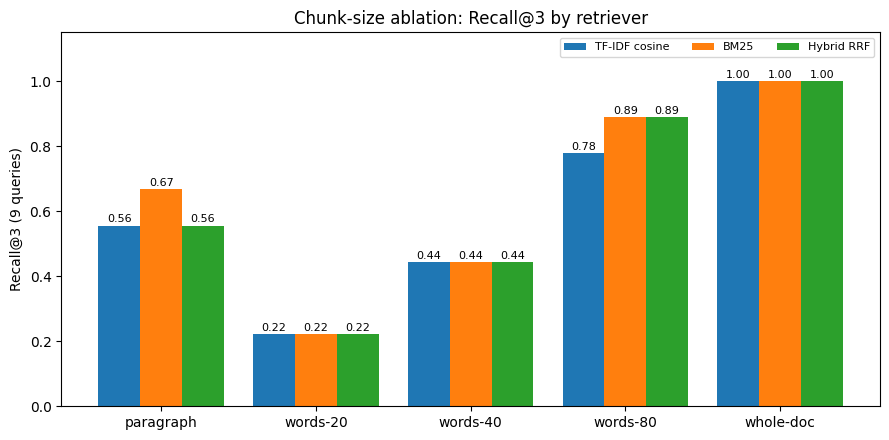

In [8]:
pivot = ablation.pivot(index="chunker", columns="retriever", values="R@3")[METHODS].loc[list(CHUNKERS)]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(pivot.index)); w = 0.27
for j, m in enumerate(METHODS):
    bars = ax.bar(x + (j - 1) * w, pivot[m].values, w, label=m)
    for b_ in bars:
        ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 0.01, f"{b_.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(pivot.index)
ax.set_ylim(0, 1.15); ax.set_ylabel("Recall@3 (9 queries)")
ax.set_title("Chunk-size ablation: Recall@3 by retriever")
ax.legend(loc="upper right", ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

## Recall@k curves (paragraph chunks)

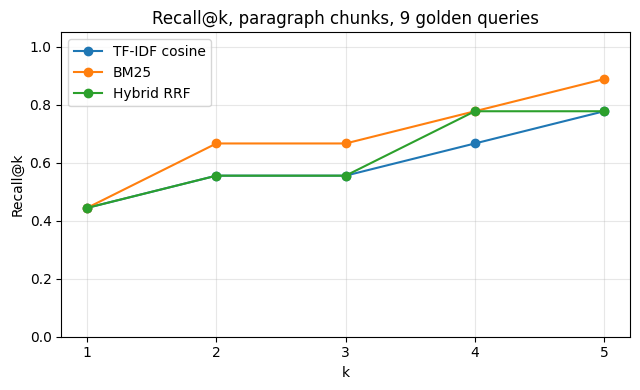

In [9]:
ks = np.arange(1, 6)
fig, ax = plt.subplots(figsize=(6.5, 4))
for m in METHODS:
    ranks = per_query_ranks("paragraph", m)
    rec = [sum(1 for r in ranks if r is not None and r <= k) / len(ranks) for k in ks]
    ax.plot(ks, rec, marker="o", label=m)
ax.set_xlabel("k"); ax.set_ylabel("Recall@k"); ax.set_xticks(ks); ax.set_ylim(0, 1.05)
ax.set_title("Recall@k, paragraph chunks, 9 golden queries"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Worked examples: query to retrieved chunks

Hybrid RRF on paragraph chunks. The third column shows which `must_include` patterns each
chunk matches.

In [10]:
chunks_p, idx_p = get_index("paragraph")

def show_example(case_id, k=3):
    c = next(x for x in cases if x["id"] == case_id)
    order, scores = search(idx_p, c["question"], "Hybrid RRF")
    print("=" * 110)
    print(f"[{c['id']}] route={c['expected_route']}  QUERY: {c['question']}")
    print("must_include:", c["must_include"])
    for r, i in enumerate(order[:k], start=1):
        matched = [p for p in c["must_include"] if re.search(p, chunks_p[i]["text"], re.I)]
        print(f"  #{r} {chunks_p[i]['id']:38s} rrf={scores[i]:.4f} matches={len(matched)}/{len(c['must_include'])}")
        print("      ", chunks_p[i]["text"][:230].replace("\n", " "), "...")
    print(f"  coverage rank r_q = {coverage_rank(order, chunks_p, c['must_include'])}")

for cid in ["v04", "v07", "v10"]:
    show_example(cid)

[v04] route=both  QUERY: I missed a payment on my Circuit City Lights order — can I just reschedule it to next month?
must_include: ['repa', "cannot|can't|can not|unable|not (be )?(re)?schedul"]
  #1 POLICY_-_01-payment-schedules#2        rrf=0.0328 matches=0/2
       Questions about a *specific* order's next payment date or amount must be answered from that order's record, not from this general policy. ...
  #2 POLICY_-02-rescheduling-payments#1     rrf=0.0323 matches=2/2
       - The **first reschedule on an order is free** and can push the date **up to 2 weeks**. - Each **subsequent reschedule on the same order costs $5** (see Fees Overview). - A maximum of **3 reschedules per order** is allowed. - A re ...
  #3 POLICY_-10-fees-overview#0             rrf=0.0317 matches=0/2
       # Fees Overview | Fee | Amount | When | |---|---|---| | Failed-payment fee | $10 | Second failed charge attempt on an installment | | Reschedule fee | $5 | Second and third reschedule on an order (first is 

## Results

In [11]:
# Final summary of the numbers used in the Results section above.
print(main_table[["hits@1", "hits@3", "hits@5", "Recall@1", "Recall@3", "Recall@5", "MRR"]].round(3).to_string())

              hits@1 hits@3 hits@5  Recall@1  Recall@3  Recall@5    MRR
retriever                                                              
TF-IDF cosine    4/9    5/9    7/9     0.444     0.556     0.778  0.578
BM25             4/9    6/9    8/9     0.444     0.667     0.889  0.617
Hybrid RRF       4/9    5/9    7/9     0.444     0.556     0.778  0.586


Measured on the 9 golden retrieval queries (paragraph chunks, 33 chunks):

| Retriever | hits@1 | hits@3 | hits@5 | Recall@1 | Recall@3 | Recall@5 | MRR |
|---|---|---|---|---|---|---|---|
| TF-IDF cosine | 4/9 | 5/9 | 7/9 | 0.444 | 0.556 | 0.778 | 0.578 |
| BM25 | 4/9 | 6/9 | 8/9 | 0.444 | 0.667 | 0.889 | 0.617 |
| Hybrid RRF | 4/9 | 5/9 | 7/9 | 0.444 | 0.556 | 0.778 | 0.586 |

- **BM25 is the best of the three on this set** (Recall@3 0.667, MRR 0.617). The hybrid RRF did not beat BM25 here; it sits between TF-IDF and BM25 on every metric.
- **Chunk size matters more than the retriever.** Recall@3 ranges from 0.222 (words-20, 116 chunks) to 0.889 (words-80, BM25 and hybrid). Under the chunk-count cut-off, whole-document chunks reach 9/9, but that is a length artefact: each whole document is one long chunk that contains most of the regexes.
- **Fixed 100-word budget (fairer comparison):** paragraph chunks reach 3/9 (TF-IDF), 4/9 (BM25), 3/9 (hybrid); whole-document chunks reach only 1/9 because a whole document averages 101 words, which exceeds the budget.
- **Failures:** query v06 (Bloom & Vine, dispute) needs all four patterns and only becomes fully covered at rank 9 (TF-IDF) and rank 10 (BM25). Query v07 (job loss, hardship) is covered at rank 6 (TF-IDF) and 5 (BM25), and its top-3 chunks never contain the human-escalation text.
- **Sanity check:** our TF-IDF matrix matches scikit-learn's `TfidfVectorizer` (same tokeniser) to a maximum absolute difference of 2.2e-16.

**Caveats.** (1) Nine queries: one query moves Recall by 0.111, so differences of one or two queries are noise. (2) The hit criterion is a regex proxy, not human relevance. Some patterns are generic (`3`, `escalat`, `human|agent`), which inflates hits for any chunk that mentions escalation or the word "3". (3) The 100-word budget was chosen a priori and was not tuned. (4) The corpus has 12 short documents, so these numbers do not transfer to large corpora.

## Conclusions
1. **Lexical retrieval is a strong baseline on policy text.** With paragraph chunks, BM25 reaches Recall@5 of 0.889 and MRR of 0.617, ahead of TF-IDF cosine (0.778, 0.578). Policy documents use precise terms (fees, dates, percentages), which BM25 rewards.
2. **Hybrid fusion did not help here.** Reciprocal Rank Fusion (Recall@5 0.778, MRR 0.586) did not beat BM25 alone. Fusion helps when the retrievers fail on different queries; with two lexical methods that share most of their errors, there is little to gain. A dense embedding retriever would be the natural second signal.
3. **Chunk size matters more than the retriever.** Recall@3 ranges from 0.222 with 20-word chunks to 0.889 with 80-word chunks. Whole documents score 9/9 at Recall@3 only because they are long; under a fixed 100-word budget, whole documents drop to 1/9 and paragraphs reach 3 to 4 of 9. Retrieval quality has to be judged together with how much context the generator receives.
4. **Limits.** There are only 9 queries (one query is 0.111 of recall), the hit definition is a regex proxy for "the answer is in the retrieved text", and one query (v06) only reaches full coverage at rank 9 to 10. These numbers are a harness demonstration, not a benchmark.

**Takeaway for the interview:** measure retrieval separately from generation, always include a lexical baseline, and treat chunking as a tuning parameter, not a default.